In [54]:
"""
SADCP through an eddy: one figure, three panels
  (a) map: ADT, TOEddies contours + center, ship track coloured by time, projection line
  (b) raw SADCP: velocity orthogonal to the ship's local heading, vs distance travelled
  (c) processed SADCP: velocity orthogonal to the best-fit section line, 3 km bins,
      vs distance along that line from the TOEddies center
On (b) and (c): TOEddies outer contour (dashed), max-speed contour (solid) and center
(dash-dot) in blue for cyclones / red for anticyclones, Nencioli center in green dashed.
"""
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.gridspec import GridSpec
from matplotlib.path import Path as MplPath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from pyproj import Geod

try:
    import geopandas as gpd
except ImportError:
    gpd = None

In [55]:
# =============================================================================
# Eddy and section
# =============================================================================
EDDIES = {
    "CE17": dict(name="CE17_20260512", eddy_type=-1, t0="2026-07-16T06:00", t1="2026-07-17T16:00"),
}
CURR = "CE17"

# =============================================================================
# Settings
# =============================================================================
SADCP_AVG = "10min"          # SADCP time averaging (~3 km at 10 kn)
USE_DETIDED = True           # use UVEL_ADCP_CORTIDE / VVEL_ADCP_CORTIDE when present
Z_SPLIT = 150.0              # m: OS150 above, OS38 below
ZMAX_SADCP = 1000.0
Z_FILL_GAP = 40.0            # m: fill vertical gaps up to this size (seam between OS150/OS38)
DS_KM = 3.0                  # bin size along the section line (panel c)
HEADING_SMOOTH_KM = 2.0      # track length used for the local heading (panel b)
CENTER_SMOOTH_DAYS = 3       # running mean on the daily TOEddies centers
R_KM = 6371.0

# Nencioli et al. (2008)
NEN_SEARCH_KM = 80.0         # candidate centers: square of +- this around the TOEddies center
NEN_GRID = 81                # candidate grid points per side (81 -> 2 km spacing)
NEN_MIN_FRAC = 0.5           # skip depth levels with fewer valid fixes than this fraction
NEN_LAYER = (30.0, 200.0)    # m: layer for the single robust center (map + print)
CENTER_BY_DEPTH = True       # True: green line = center at every depth; False: layer center only
SECTION_X_FROM = "start"     # panel (c) x: "start" = 0 at the start of the section line,

VLIM = None                  # colour limit of the sections [m/s]; None = 98th percentile
NEN_COLOR = "tab:green"
CMAP = cmocean.cm.balance

# =============================================================================
# Paths
# =============================================================================
BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
DIR_TRACKS = BASE / "eddies"
OUT_DIR = BASE / "figures"

crs = ccrs.PlateCarree()

In [56]:
# =============================================================================
# Data loading (unchanged from your notebook)
# =============================================================================
def _find(ds, names, required=True):
    for n in names:
        if n in ds.variables:
            return n
    low = {k.lower(): k for k in ds.variables}
    for n in names:
        if n.lower() in low:
            return low[n.lower()]
    if required:
        raise KeyError(f"None of {names} in {list(ds.variables)}")
    return None


_SADCP_CACHE = {}


def load_sadcp_raw(path):
    """Full-resolution SADCP as Dataset(time, z) with u, v, lat, lon (QC flag == 1)."""
    if path in _SADCP_CACHE:
        return _SADCP_CACHE[path]
    ds = xr.open_dataset(path)
    tn = _find(ds, ["JULD_ADCP", "TIME", "time", "JULD"])
    zn = _find(ds, ["DEPH", "DEPTH", "depth"])
    un = _find(ds, ["UVEL_ADCP_CORTIDE"], required=False) if USE_DETIDED else None
    vn = _find(ds, ["VVEL_ADCP_CORTIDE"], required=False) if USE_DETIDED else None
    if un is None or vn is None:
        un, vn = _find(ds, ["UVEL_ADCP"]), _find(ds, ["VVEL_ADCP"])
    fn = _find(ds, ["CAS_CURRENT_FLAG"], required=False)
    print(f"  {Path(path).name}: using {un}, {vn}")
    tdim = ds[tn].dims[0]
    U = ds[un].squeeze(drop=True)
    zdim = [d for d in U.dims if d != tdim][0]
    u = U.transpose(tdim, zdim).values.astype(float)
    v = ds[vn].squeeze(drop=True).transpose(tdim, zdim).values.astype(float)
    traw = ds[tn].values
    time = (pd.to_datetime(traw) if np.issubdtype(traw.dtype, np.datetime64)
            else pd.Timestamp("1950-01-01") + pd.to_timedelta(traw.astype(float), unit="D"))
    if fn is not None:
        fl = ds[fn].squeeze(drop=True)
        fl = fl.transpose(tdim, zdim).values if zdim in fl.dims else fl.values[:, None]
        good = (fl == 1) if np.issubdtype(fl.dtype, np.number) else \
            np.char.strip(np.char.decode(fl.astype("S"), "ascii", "ignore")) == "1"
        good = np.broadcast_to(good, u.shape)
        u, v = np.where(good, u, np.nan), np.where(good, v, np.nan)
    u[np.abs(u) > 5] = np.nan
    v[np.abs(v) > 5] = np.nan
    zda = ds[zn].squeeze(drop=True)
    z = np.abs(np.nanmedian(zda.transpose(tdim, zdim).values, axis=0) if zda.ndim == 2
               else zda.values).astype(float)
    keepz = np.isfinite(z)
    lat = ds[_find(ds, ["LATITUDE", "lat"])].squeeze(drop=True).values.astype(float)
    lon = ds[_find(ds, ["LONGITUDE", "lon"])].squeeze(drop=True).values.astype(float)
    lat = np.where(np.abs(lat) <= 90, lat, np.nan)
    lon = np.where(np.abs(lon) <= 360, lon, np.nan)
    lon = np.where(lon > 180, lon - 360, lon)
    out = xr.Dataset({"u": (("time", "z"), u[:, keepz]), "v": (("time", "z"), v[:, keepz]),
                      "lat": ("time", lat), "lon": ("time", lon)},
                     coords={"time": np.asarray(time, "datetime64[ns]"), "z": z[keepz]})
    out = out.isel(time=np.asarray(pd.notna(time))).sortby("time").sortby("z")
    out = out.isel(time=~pd.Index(out.time.values).duplicated())
    ds.close()
    _SADCP_CACHE[path] = out
    return out


def sadcp_window(t0, t1):
    """OS150 above Z_SPLIT + OS38 below, averaged over SADCP_AVG, inside [t0, t1].
    Returns a dict of numpy arrays: time, lon, lat, z, u (nt, nz), v (nt, nz)."""
    parts = []
    for inst, f in SADCP_FILES.items():
        if not f.exists():
            print(f"  ! missing {f}")
            continue
        d = load_sadcp_raw(f).sel(time=slice(t0, t1)).resample(time=SADCP_AVG).mean()
        zz = d.z.values
        keep = zz <= Z_SPLIT if inst == "OS150" else (zz > Z_SPLIT) & (zz <= ZMAX_SADCP)
        parts.append(d.isel(z=np.where(keep)[0]))
    if not parts:
        raise FileNotFoundError("no SADCP file found")
    out = parts[0]
    for p in parts[1:]:
        p = p.reindex(time=out.time)
        out = xr.Dataset({"u": xr.concat([out.u, p.u], "z"), "v": xr.concat([out.v, p.v], "z"),
                          "lat": out.lat.fillna(p.lat), "lon": out.lon.fillna(p.lon)})
    out = out.sortby("z")
    ok = np.isfinite(out.lat.values) & np.isfinite(out.lon.values) & np.isfinite(out.u.values).any(1)
    out = out.isel(time=ok)
    return dict(time=out.time.values, lon=out.lon.values, lat=out.lat.values, z=out.z.values,
                u=out.u.values, v=out.v.values)


def load_track(name):
    f = next(iter(sorted(DIR_TRACKS.rglob(f"tracked_eddy_{name}.csv"))), None)
    if f is None:
        raise FileNotFoundError(f"tracked_eddy_{name}.csv not found under {DIR_TRACKS}")
    return pd.read_csv(f, parse_dates=["date"])


def center_at(tr, times):
    """TOEddies center at given times: daily centers at 12:00, running mean, linear interp."""
    t = tr.date + pd.Timedelta(hours=12)
    lon = tr.lon.rolling(CENTER_SMOOTH_DAYS, center=True, min_periods=1).mean().values
    lat = tr.lat.rolling(CENTER_SMOOTH_DAYS, center=True, min_periods=1).mean().values
    tq = pd.to_datetime(times).values.astype("datetime64[s]").astype(float)
    tt = t.values.astype("datetime64[s]").astype(float)
    return np.interp(tq, tt, lon), np.interp(tq, tt, lat)


def adt_day(day):
    """ADT of one day as a DataArray(lat, lon), lon in [-180, 180], sorted."""
    d = pd.Timestamp(day)
    tags = (d.strftime("%Y-%m-%d"), d.strftime("%Y%m%d"))
    f = next((f for f in sorted(glob.glob(str(DIR_SSH / "*.nc")))
              if any(t in Path(f).name for t in tags)), None)
    if f is None:
        print(f"  ! no ADT file for {d:%Y-%m-%d}")
        return None
    ds = xr.open_dataset(f)
    ds = ds.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon"}.items()
                    if k in ds.variables})
    a = ds["adt"]
    if "time" in a.dims:
        a = a.isel(time=0)
    a = a.assign_coords(lon=xr.where(a.lon > 180, a.lon - 360, a.lon)).sortby(["lat", "lon"])
    return a.load()


def _xy_contour(geom):
    """Outline (lon, lat) of a (Multi)Polygon / LineString, NaNs removed, lon in [-180, 180]."""
    if geom is None or geom.is_empty:
        return None
    if geom.geom_type == "Polygon":
        xy = np.asarray(geom.exterior.coords)
    elif geom.geom_type == "MultiPolygon":
        xy = np.asarray(max(geom.geoms, key=lambda g: g.area).exterior.coords)
    elif geom.geom_type in ("LineString", "LinearRing"):
        xy = np.asarray(geom.coords)
    elif geom.geom_type == "MultiLineString":
        xy = np.asarray(max(geom.geoms, key=lambda g: g.length).coords)
    else:
        return None
    xy = xy[:, :2][np.isfinite(xy[:, :2]).all(axis=1)]
    xy[:, 0] = np.where(xy[:, 0] > 180, xy[:, 0] - 360, xy[:, 0])
    return xy if len(xy) > 2 else None


def toeddies_eddy(date, lon, lat, cyc=True):
    """TOEddies eddy nearest to (lon, lat) on `date`: center (lon, lat), maxspeed and
    outer contours (N x 2 lon/lat arrays), index in the file, distance [km]."""
    if gpd is None:
        raise ImportError("geopandas is needed to read the TOEddies files")
    kind = "cyclones" if cyc else "anticyclones"
    d = pd.Timestamp(date)

    def find(part):
        for folder in DIR_EDDIES.values():
            for tag in (d.strftime("%Y%m%d"), d.strftime("%Y-%m-%d")):
                for f in sorted(glob.glob(str(Path(folder) / f"*{tag}*"))):
                    name = Path(f).name.lower()
                    if (kind == "anticyclones") != ("anticyclon" in name):
                        continue        # "cyclones" is also inside "anticyclones"
                    if part in name and name.endswith((".geojson", ".json", ".shp")):
                        return gpd.read_file(f)
        return None

    cen = find("centers")
    if cen is None:
        raise FileNotFoundError(f"no TOEddies {kind} centers for {d:%Y-%m-%d}")
    ok = (cen.geometry.notna() & ~cen.geometry.is_empty).values
    clon = np.full(len(cen), np.nan)
    clat = np.full(len(cen), np.nan)
    clon[ok], clat[ok] = cen.geometry[ok].x.values, cen.geometry[ok].y.values
    clon = np.where(clon > 180, clon - 360, clon)
    dist = R_KM * np.hypot(np.deg2rad(clon - lon) * np.cos(np.deg2rad(lat)),
                           np.deg2rad(clat - lat))
    i = int(np.nanargmin(dist))

    def contour(part):
        g = find(part)
        if g is None or len(g) == 0:
            return None
        if len(g) == len(cen):                      # same order as the centers file
            xy = _xy_contour(g.geometry.iloc[i])
            if xy is not None:
                return xy
        p = cen.geometry.iloc[i]
        for geom in g.geometry:                     # otherwise: the contour holding the center
            if geom is not None and not geom.is_empty and geom.geom_type.endswith("Polygon") \
                    and geom.contains(p):
                return _xy_contour(geom)
        return None

    print(f"  TOEddies {kind[:-1]} #{i} on {d:%Y-%m-%d}: center {clon[i]:.3f}, {clat[i]:.3f} "
          f"({dist[i]:.1f} km from the tracked center)")
    return dict(center=(clon[i], clat[i]), maxspeed=contour("maxspeed"),
                outer=contour("outcontour"), index=i, date=d.normalize())

In [57]:
# =============================================================================
# Geometry
# =============================================================================
geod = Geod(ellps="WGS84")


def to_xy(lon, lat, lon0, lat0):
    """Local tangent plane, km."""
    x = np.deg2rad(np.asarray(lon, float) - lon0) * R_KM * np.cos(np.deg2rad(lat0))
    y = np.deg2rad(np.asarray(lat, float) - lat0) * R_KM
    return x, y


def to_lonlat(x, y, lon0, lat0):
    lon = lon0 + np.rad2deg(np.asarray(x, float) / (R_KM * np.cos(np.deg2rad(lat0))))
    lat = lat0 + np.rad2deg(np.asarray(y, float) / R_KM)
    return lon, lat


def fit_line(x, y):
    """Principal axis of the points: origin, along unit vector (direction of travel),
    normal unit vector (LEFT of travel)."""
    ok = np.isfinite(x) & np.isfinite(y)
    xm, ym = x[ok].mean(), y[ok].mean()
    w, vec = np.linalg.eigh(np.cov(np.vstack([x[ok] - xm, y[ok] - ym])))
    es = vec[:, np.argmax(w)]
    xi, yi = x[ok][[0, -1]], y[ok][[0, -1]]
    if (xi[1] - xi[0]) * es[0] + (yi[1] - yi[0]) * es[1] < 0:
        es = -es
    return np.array([xm, ym]), es, np.array([-es[1], es[0]])


def bin_columns(coord, vals, edges, nmin=1):
    """Mean of vals (n, nz) in bins of coord. Returns centers, (nbins, nz) mean, counts."""
    idx = np.digitize(coord, edges) - 1
    out = np.full((len(edges) - 1, vals.shape[1]), np.nan)
    cnt = np.zeros(len(edges) - 1, int)
    for b in range(len(edges) - 1):
        m = idx == b
        cnt[b] = m.sum()
        if cnt[b] >= nmin:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                out[b] = np.nanmean(vals[m], axis=0)
    return 0.5 * (edges[:-1] + edges[1:]), out, cnt


def fill_z_gaps(V, z, max_gap=Z_FILL_GAP):
    """Linear interpolation in depth across interior gaps no thicker than max_gap."""
    V = V.copy()
    for i in range(V.shape[0]):
        ok = np.isfinite(V[i])
        if ok.sum() < 2:
            continue
        zk = z[ok]
        bad = np.where(~ok & (z > zk.min()) & (z < zk.max()))[0]
        if not len(bad):
            continue
        j = np.searchsorted(zk, z[bad])
        small = (zk[j] - zk[j - 1]) <= max_gap
        V[i, bad[small]] = np.interp(z[bad[small]], zk, V[i, ok])
    return V


def along_track_distance(lon, lat):
    """Cumulative geodesic distance along the track [m]."""
    lon = np.asarray(lon, float)
    lat = np.asarray(lat, float)
    ok = np.isfinite(lon) & np.isfinite(lat)
    dist = np.full(lon.shape, np.nan)
    idx = np.flatnonzero(ok)
    if idx.size == 0:
        return dist
    _, _, seg = geod.inv(lon[idx[:-1]], lat[idx[:-1]], lon[idx[1:]], lat[idx[1:]])
    dist[idx] = np.concatenate([[0.0], np.cumsum(seg)])
    return dist


def track_heading(lon, lat, smooth_km=HEADING_SMOOTH_KM):
    """Ship course (deg clockwise from north) over +- smooth_km/2 of track; NaN on station."""
    lon = np.asarray(lon, float)
    lat = np.asarray(lat, float)
    x = along_track_distance(lon, lat) / 1000.0
    ok = np.isfinite(x) & np.isfinite(lon) & np.isfinite(lat)
    heading = np.full(lon.shape, np.nan)
    if ok.sum() < 2:
        return heading
    xs, first = np.unique(x[ok], return_index=True)
    lons, lats = lon[ok][first], lat[ok][first]
    if xs.size < 2:
        return heading
    half = smooth_km / 2.0
    xa = np.clip(x[ok] - half, xs[0], xs[-1])
    xb = np.clip(x[ok] + half, xs[0], xs[-1])
    az, _, d = geod.inv(np.interp(xa, xs, lons), np.interp(xa, xs, lats),
                        np.interp(xb, xs, lons), np.interp(xb, xs, lats))
    heading[ok] = np.where(d > 250.0 * smooth_km, az, np.nan) % 360.0
    return heading


def orthogonal_velocity(lon, lat, u, v):
    """Velocity perpendicular to the ship's local course, + to the LEFT of travel."""
    az = np.deg2rad(track_heading(lon, lat))
    nx, ny = -np.cos(az)[:, None], np.sin(az)[:, None]
    return u * nx + v * ny


def crossings_along_track(lon, lat, x, xy):
    """x where the ship track enters / leaves contour xy (midpoint of the two fixes)."""
    ok = np.isfinite(lon) & np.isfinite(lat) & np.isfinite(x)
    if xy is None or ok.sum() < 2:
        return np.array([])
    idx = np.flatnonzero(ok)
    io = MplPath(xy).contains_points(np.c_[lon[idx], lat[idx]])
    k = np.flatnonzero(io[1:] != io[:-1])
    return 0.5 * (x[idx[k]] + x[idx[k + 1]])


def crossings_on_line(xy, to_sn):
    """s where contour xy crosses the straight section line (n = 0)."""
    if xy is None:
        return np.array([])
    s, n = to_sn(xy[:, 0], xy[:, 1])
    k = np.flatnonzero(np.sign(n[:-1]) * np.sign(n[1:]) < 0)
    return s[k] - n[k] * (s[k + 1] - s[k]) / (n[k + 1] - n[k])


def nearest_fix(lon_c, lat_c, lon, lat):
    """Index of the fix closest to (lon_c, lat_c) and that distance [km]."""
    d = R_KM * np.hypot(np.deg2rad(lon - lon_c) * np.cos(np.deg2rad(lat_c)),
                        np.deg2rad(lat - lat_c))
    j = int(np.nanargmin(d))
    return j, float(d[j])

In [58]:
# =============================================================================
# Nencioli et al. (2008): your algorithm, corrected and vectorised
# =============================================================================
def nencioli_center(lon, lat, u, v, lon_c0, lat_c0, search_km=NEN_SEARCH_KM, n_grid=NEN_GRID,
                    min_frac=NEN_MIN_FRAC):
    """
    Eddy center from the velocities measured along a ship track (Nencioli et al. 2008).

    For every candidate center (lon2, lat2) of a square grid (your WL..EL, SL..NL box,
    here +- search_km around lon_c0, lat_c0), every measured velocity is split into
    radial and tangential components about that candidate. The center is the candidate
    where the RMS of the radial velocity is smallest. Done for each depth at once.

    lon, lat : (nfix,)          positions of the measurements
    u, v     : (nfix, nz)       velocities (east, north)
    Returns a dict of (nz,) arrays: lon, lat (center), rms (min radial RMS), mtg (mean
    tangential velocity there, + anticlockwise), edge (min on the grid edge), ok (enough
    data), plus the grid and the full RMS field rms_grid (n_grid, n_grid, nz).

    Fixes compared with the original loop:
      * angles in radians (cos/sin were given degrees);
      * dx, dy are signed east/north distances from the candidate to the measurement,
        so arctan2 gives the right angle in every quadrant (no quadrant corrections);
      * radial, tangent, Elliptic_RMS, Elliptic_Mtg are separate arrays (they were the
        same array: `radial = A; tangent = radial` makes them aliases);
      * the minimum is located with unravel_index on the 2-D grid (np.where(...)[0] only
        gave the row);
      * the RMS is divided by the number of valid values, not the full length;
      * the SADCP arrays are not modified in place.
    """
    R, f = R_KM, np.pi / 180
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    u, v = np.atleast_2d(np.asarray(u, float).T).T, np.atleast_2d(np.asarray(v, float).T).T

    # candidate grid
    dlat = search_km / (R * f)
    dlon = dlat / np.cos(lat_c0 * f)
    lon2 = np.linspace(lon_c0 - dlon, lon_c0 + dlon, n_grid)
    lat2 = np.linspace(lat_c0 - dlat, lat_c0 + dlat, n_grid)
    LON, LAT = np.meshgrid(lon2, lat2)                       # (ny, nx)
    lc, la = LON.ravel()[:, None], LAT.ravel()[:, None]      # (ncand, 1)

    # signed distances candidate -> measurement [km] and angle from east, anticlockwise
    dx = (lon[None, :] - lc) * f * R * np.cos(la * f)
    dy = (lat[None, :] - la) * f * R
    angle = np.arctan2(dy, dx)                               # (ncand, nfix)
    C, S = np.cos(angle), np.sin(angle)

    # radial = U cos + V sin, tangential = -U sin + V cos, for every candidate and depth
    valid = np.isfinite(u) & np.isfinite(v) & (np.isfinite(lon) & np.isfinite(lat))[:, None]
    U, V = np.where(valid, u, 0.0), np.where(valid, v, 0.0)
    C, S = np.nan_to_num(C), np.nan_to_num(S)
    cnt = valid.sum(axis=0).astype(float)                    # valid values per depth
    with np.errstate(invalid="ignore", divide="ignore"):
        rad2 = (C ** 2) @ (U ** 2) + 2 * (C * S) @ (U * V) + (S ** 2) @ (V ** 2)
        rms = np.sqrt(rad2 / cnt)                            # (ncand, nz)
        mtg = ((-S) @ U + C @ V) / cnt

    nz = u.shape[1]
    ok = cnt >= min_frac * np.isfinite(lon).sum()
    k = np.zeros(nz, int)
    k[ok] = np.nanargmin(rms[:, ok], axis=0)
    iy, ix = np.unravel_index(k, LON.shape)
    edge = (iy == 0) | (iy == n_grid - 1) | (ix == 0) | (ix == n_grid - 1)
    nan = lambda a: np.where(ok, a, np.nan)
    return dict(lon=nan(lon2[ix]), lat=nan(lat2[iy]), rms=nan(rms[k, np.arange(nz)]),
                mtg=nan(mtg[k, np.arange(nz)]), edge=edge & ok, ok=ok,
                grid_lon=lon2, grid_lat=lat2, rms_grid=rms.reshape(n_grid, n_grid, nz))

In [59]:
# =============================================================================
# The figure
# =============================================================================
def mark_section(ax, x_oc, x_ms, x_c, x_nen, z, col, vertical_nen):
    """TOEddies outer (dashed), max speed (solid), center (dash-dot) in the eddy colour,
    Nencioli center in green dashed (one x per depth, or one x)."""
    for xv in x_oc:
        ax.axvline(xv, color=col, ls="--", lw=1.3)
    for xv in x_ms:
        ax.axvline(xv, color=col, ls="-", lw=1.6)
    if np.isfinite(x_c):
        ax.axvline(x_c, color=col, ls="-.", lw=1.6)
    if vertical_nen:
        if np.isfinite(x_nen):
            ax.axvline(x_nen, color=NEN_COLOR, ls="--", lw=2.2)
    else:
        ax.plot(x_nen, z, color=NEN_COLOR, ls="--", lw=2.2)


def three_panel_figure(cfg):
    t0, t1 = cfg["t0"], cfg["t1"]
    tmid = pd.Timestamp(t0) + (pd.Timestamp(t1) - pd.Timestamp(t0)) / 2
    cyc = cfg["eddy_type"] == -1
    col = "tab:blue" if cyc else "tab:red"

    # ---- data ------------------------------------------------------------
    tr = load_track(cfg["name"])
    tlon, tlat = (float(a[0]) for a in center_at(tr, [tmid]))
    edd = toeddies_eddy(tmid, tlon, tlat, cyc=cyc)           # contours + center, middle day
    clon, clat = edd["center"]
    sad = sadcp_window(t0, t1)
    lon, lat, z, u, v = sad["lon"], sad["lat"], sad["z"], sad["u"], sad["v"]
    hours = (sad["time"] - sad["time"][0]) / np.timedelta64(1, "h")

    # ---- (b) raw: local heading, distance travelled ------------------------
    x_raw = along_track_distance(lon, lat) / 1000.0
    v_raw = orthogonal_velocity(lon, lat, u, v)

    # ---- (c) processed: best-fit line, 3 km bins, 0 = TOEddies center -------
    lon0, lat0 = float(np.nanmean(lon)), float(np.nanmean(lat))
    xs, ys = to_xy(lon, lat, lon0, lat0)
    origin, es, en = fit_line(xs, ys)

    def to_sn(lo, la):
        px, py = to_xy(lo, la, lon0, lat0)
        return ((px - origin[0]) * es[0] + (py - origin[1]) * es[1],
                (px - origin[0]) * en[0] + (py - origin[1]) * en[1])

    s, n = to_sn(lon, lat)
    s_c, d_c = (float(a) for a in to_sn(clon, clat))
    heading = (np.degrees(np.arctan2(es[0], es[1])) + 360) % 360
    vn = u * en[0] + v * en[1]
    xg, V, _ = bin_columns(s, vn, np.arange(np.floor(s.min()), np.ceil(s.max()) + DS_KM, DS_KM))
    V = fill_z_gaps(V, z)
    s_ref = float(np.nanmin(s)) if SECTION_X_FROM == "start" else s_c
    x_sec = xg - s_ref
    # ---- Nencioli center ----------------------------------------------------
    lay = (z >= NEN_LAYER[0]) & (z <= NEN_LAYER[1])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        ul, vl = np.nanmean(u[:, lay], axis=1), np.nanmean(v[:, lay], axis=1)
    nl = nencioli_center(lon, lat, ul[:, None], vl[:, None], clon, clat)
    nlon, nlat = float(nl["lon"][0]), float(nl["lat"][0])
    nd = nencioli_center(lon, lat, u, v, clon, clat)

    # ---- positions on the two section axes ---------------------------------
    j_c, d_c_ship = nearest_fix(clon, clat, lon, lat)
    raw = dict(oc=crossings_along_track(lon, lat, x_raw, edd["outer"]),
               ms=crossings_along_track(lon, lat, x_raw, edd["maxspeed"]),
               c=x_raw[j_c])
    sec = dict(oc=crossings_on_line(edd["outer"], to_sn) - s_ref,
           ms=crossings_on_line(edd["maxspeed"], to_sn) - s_ref, c=s_c - s_ref)
    s_nl = float(to_sn(nlon, nlat)[0]) - s_ref
    j_nl, d_nl_ship = nearest_fix(nlon, nlat, lon, lat)
    if CENTER_BY_DEPTH:
        sec["nen"] = to_sn(nd["lon"], nd["lat"])[0] - s_ref
        raw["nen"] = np.full(len(z), np.nan)
        for i in np.flatnonzero(nd["ok"]):
            raw["nen"][i] = x_raw[nearest_fix(nd["lon"][i], nd["lat"][i], lon, lat)[0]]
    else:
        sec["nen"], raw["nen"] = s_nl, x_raw[j_nl]

    # ---- figure layout -------------------------------------------------------
    fig = plt.figure(figsize=(19, 9))
    gs = GridSpec(2, 3, figure=fig, width_ratios=[1.15, 2, 0.035], wspace=0.18, hspace=0.3)
    proj = ccrs.Mercator(central_longitude=lon0)
    axm = fig.add_subplot(gs[:, 0], projection=proj)
    axb = fig.add_subplot(gs[0, 1])
    axc = fig.add_subplot(gs[1, 1])
    cax = fig.add_subplot(gs[:, 2])

    # ---- (a) map --------------------------------------------------------------
    ext_lon = np.r_[lon, nlon, clon] if edd["outer"] is None else np.r_[lon, nlon, edd["outer"][:, 0]]
    ext_lat = np.r_[lat, nlat, clat] if edd["outer"] is None else np.r_[lat, nlat, edd["outer"][:, 1]]
    pad = 0.3
    extent = [np.nanmin(ext_lon) - pad, np.nanmax(ext_lon) + pad,
              np.nanmin(ext_lat) - pad, np.nanmax(ext_lat) + pad]
    axm.set_extent(extent, crs=crs)
    axm.add_feature(cfeature.LAND, facecolor="0.6", edgecolor="k", zorder=3)
    gl = axm.gridlines(draw_labels=True, lw=0.3, color="0.5", alpha=0.5)
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"size": 8}

    a = adt_day(tmid)
    if a is not None:
        a = a.sel(lon=slice(extent[0] - 0.5, extent[1] + 0.5),
                  lat=slice(extent[2] - 0.5, extent[3] + 0.5))
        pm = axm.pcolormesh(a.lon, a.lat, a, cmap="Greys_r", shading="auto", transform=crs,
                            zorder=0)
        axm.contour(a.lon, a.lat, a, levels=np.arange(-2, 3, 0.05), colors="0.35",
                    linewidths=0.4, transform=crs, zorder=1)
        cb = fig.colorbar(pm, ax=axm, orientation="horizontal", shrink=0.7, pad=0.06)
        cb.set_label(f"ADT {tmid:%Y-%m-%d} [m] (contours every 5 cm)")

    if edd["outer"] is not None:
        axm.plot(edd["outer"][:, 0], edd["outer"][:, 1], color=col, ls="--", lw=1.5,
                 transform=crs, zorder=5)
    if edd["maxspeed"] is not None:
        axm.plot(edd["maxspeed"][:, 0], edd["maxspeed"][:, 1], color=col, ls="-", lw=2,
                 transform=crs, zorder=5)

    axm.plot(lon, lat, "-", color="k", lw=0.6, transform=crs, zorder=6)
    sc = axm.scatter(lon, lat, c=hours, cmap="viridis", s=12, edgecolors="none",
                     transform=crs, zorder=7)
    tcb = fig.colorbar(sc, ax=axm, orientation="vertical", shrink=0.5, pad=0.02)
    tcb.set_label(f"Hours since {pd.Timestamp(sad['time'][0]):%m-%d %H:%M}")

    # section line with its x axis direction, and the foot of the TOEddies center
    smin, smax = np.nanmin(s), np.nanmax(s)
    llon, llat = to_lonlat(origin[0] + np.array([smin, smax]) * es[0],
                           origin[1] + np.array([smin, smax]) * es[1], lon0, lat0)
    tf = crs._as_mpl_transform(axm)
    axm.annotate("", xy=(llon[1], llat[1]), xytext=(llon[0], llat[0]), xycoords=tf,
                 textcoords=tf, arrowprops=dict(arrowstyle="->", color="m", lw=1.8), zorder=8)
    flon, flat = to_lonlat(origin[0] + s_c * es[0], origin[1] + s_c * es[1], lon0, lat0)
    axm.plot([clon, flon], [clat, flat], ":", color="m", lw=1.2, transform=crs, zorder=8)
    axm.plot(flon, flat, "|", color="m", ms=12, mew=2, transform=crs, zorder=8)

    axm.plot(clon, clat, "X", color=col, ms=11, mec="k", transform=crs, zorder=9)
    if CENTER_BY_DEPTH:
        axm.scatter(nd["lon"], nd["lat"], s=6, c=NEN_COLOR, transform=crs, zorder=9)
    axm.plot(nlon, nlat, "o", color=NEN_COLOR, ms=10, mec="k", transform=crs, zorder=10)

    axm.legend(handles=[
        mlines.Line2D([], [], color=col, ls="--", label="TOEddies outer contour"),
        mlines.Line2D([], [], color=col, ls="-", lw=2, label="TOEddies max-speed contour"),
        mlines.Line2D([], [], color=col, marker="X", mec="k", ls="", ms=9, label="TOEddies center"),
        mlines.Line2D([], [], color="k", marker="o", ms=4, lw=0.6, label="Ship track"),
        mlines.Line2D([], [], color="m", lw=1.8, marker=">", label=f"Section line"),
        mlines.Line2D([], [], color=NEN_COLOR, marker="o", mec="k", ls="", ms=8,
                      label=f"Nencioli center"),
    ]).set_zorder(20)
    
    axm.set_title(f"(a) {cfg['name']}  (TOEddies {edd['date']:%Y-%m-%d})", loc="left", fontsize=10)

    # ---- (b) and (c) sections -------------------------------------------------
    vlim = VLIM
    if vlim is None:
        vals = np.abs(np.r_[v_raw.ravel(), V.ravel()])
        vlim = max(0.1, np.round(np.nanpercentile(vals[np.isfinite(vals)], 98) * 10) / 10)
    kw = dict(cmap=CMAP, vmin=-vlim, vmax=vlim, shading="auto")
    pb = axb.pcolormesh(x_raw, z, v_raw.T, **kw)
    axc.pcolormesh(x_sec, z, V.T, **kw)
    fig.colorbar(pb, cax=cax).set_label("Velocity [m s$^{-1}$]")

    mark_section(axb, raw["oc"], raw["ms"], raw["c"], raw["nen"], z, col, not CENTER_BY_DEPTH)
    mark_section(axc, sec["oc"], sec["ms"], sec["c"], sec["nen"], z, col, not CENTER_BY_DEPTH)

    axb.set_xlim(np.nanmin(x_raw), np.nanmax(x_raw))
    axc.set_xlim(0 if SECTION_X_FROM == "start" else np.nanmin(x_sec), np.nanmax(x_sec))
    for ax in (axb, axc):
        ax.set_ylim(np.nanmax(z), 0)
        ax.set_ylabel("Depth [m]")
        if es[0] < 0:                      # ship going west: put west on the left, as on the map
            ax.invert_xaxis()
    axb.set_xlabel("Distance travelled by the ship [km]")
    axc.set_xlabel(f"Distance along the section line [km]")
    axb.set_title("(b) Raw SADCP: velocity perpendicular to the ship's local heading ", loc="left", fontsize=10)
    axc.set_title(f"(c) Processed SADCP: velocity perpendicular to the section line {DS_KM:.0f} km bins", loc="left", fontsize=10)

    nen_lab = "Nencioli center"
    axb.legend(handles=[
        mlines.Line2D([], [], color=col, ls="--", label="TOEddies outer contour"),
        mlines.Line2D([], [], color=col, ls="-", lw=1.6, label="TOEddies max-speed contour"),
        mlines.Line2D([], [], color=col, ls="-.", lw=1.6,
                      label=f"TOEddies center (ship's closest pass, {d_c_ship:.0f} km)"),
        mlines.Line2D([], [], color=NEN_COLOR, ls="--", lw=2.2, label=nen_lab),
    ], fontsize=7, loc="lower left", framealpha=0.9)

    fig.suptitle(f"{cfg['name']}: {pd.Timestamp(t0):%Y-%m-%d %H:%M} → {pd.Timestamp(t1):%Y-%m-%d %H:%M}", fontsize=12, y=0.97)

    # ---- printout ------------------------------------------------------------------
    print(f"\nTOEddies center       : {clon:.3f}E {clat:.3f}N, {d_c:+.1f} km across the line "
          f"(ship passes {d_c_ship:.1f} km from it)")
    print(f"Nencioli center {NEN_LAYER[0]:.0f}-{NEN_LAYER[1]:.0f} m: {nlon:.3f}E {nlat:.3f}N, "
          f"x = {s_nl:+.1f} km on panel (c), x = {x_raw[j_nl]:.1f} km on panel (b)"
          + ("  ! on the edge of the search box" if nl["edge"][0] else ""))
    print(f"Nencioli per depth    : {nd['ok'].sum()} / {len(z)} levels solved, "
          f"{nd['edge'].sum()} on the edge of the +-{NEN_SEARCH_KM:.0f} km box (unreliable)")
    print(f"Contour crossings, panel (b): outer {np.round(raw['oc'], 1)}, max speed {np.round(raw['ms'], 1)}")
    print(f"Contour crossings, panel (c): outer {np.round(sec['oc'], 1)}, max speed {np.round(sec['ms'], 1)}")
    if len(sec["ms"]) == 0:
        print("  (the section line does not cross the max-speed contour)")

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    out = OUT_DIR / f"{cfg['name']}_SADCP_3panel.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    print(f"saved {out}")
    plt.show()
    return dict(sad=sad, edd=edd, x_raw=x_raw, v_raw=v_raw, x_sec=x_sec, V=V,
                nen_layer=nl, nen=nd, raw=raw, sec=sec)

  TOEddies cyclone #24 on 2026-07-16: center 12.812, -37.062 (7.0 km from the tracked center)
  WHIRLS_NB150_TOT_osite.nc: using UVEL_ADCP_CORTIDE, VVEL_ADCP_CORTIDE
  WHIRLS_BB38_TOT_osite.nc: using UVEL_ADCP_CORTIDE, VVEL_ADCP_CORTIDE

TOEddies center       : 12.812E -37.062N, +18.6 km across the line (ship passes 12.5 km from it)
Nencioli center 30-200 m: 12.858E -36.991N, x = +139.7 km on panel (c), x = 167.0 km on panel (b)
Nencioli per depth    : 51 / 51 levels solved, 0 on the edge of the +-80 km box (unreliable)
Contour crossings, panel (b): outer [], max speed [ 51.1 260.3]
Contour crossings, panel (c): outer [-98.6 239.3], max speed [ 39.  205.9]
saved /Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/CE17_20260512_SADCP_3panel.png


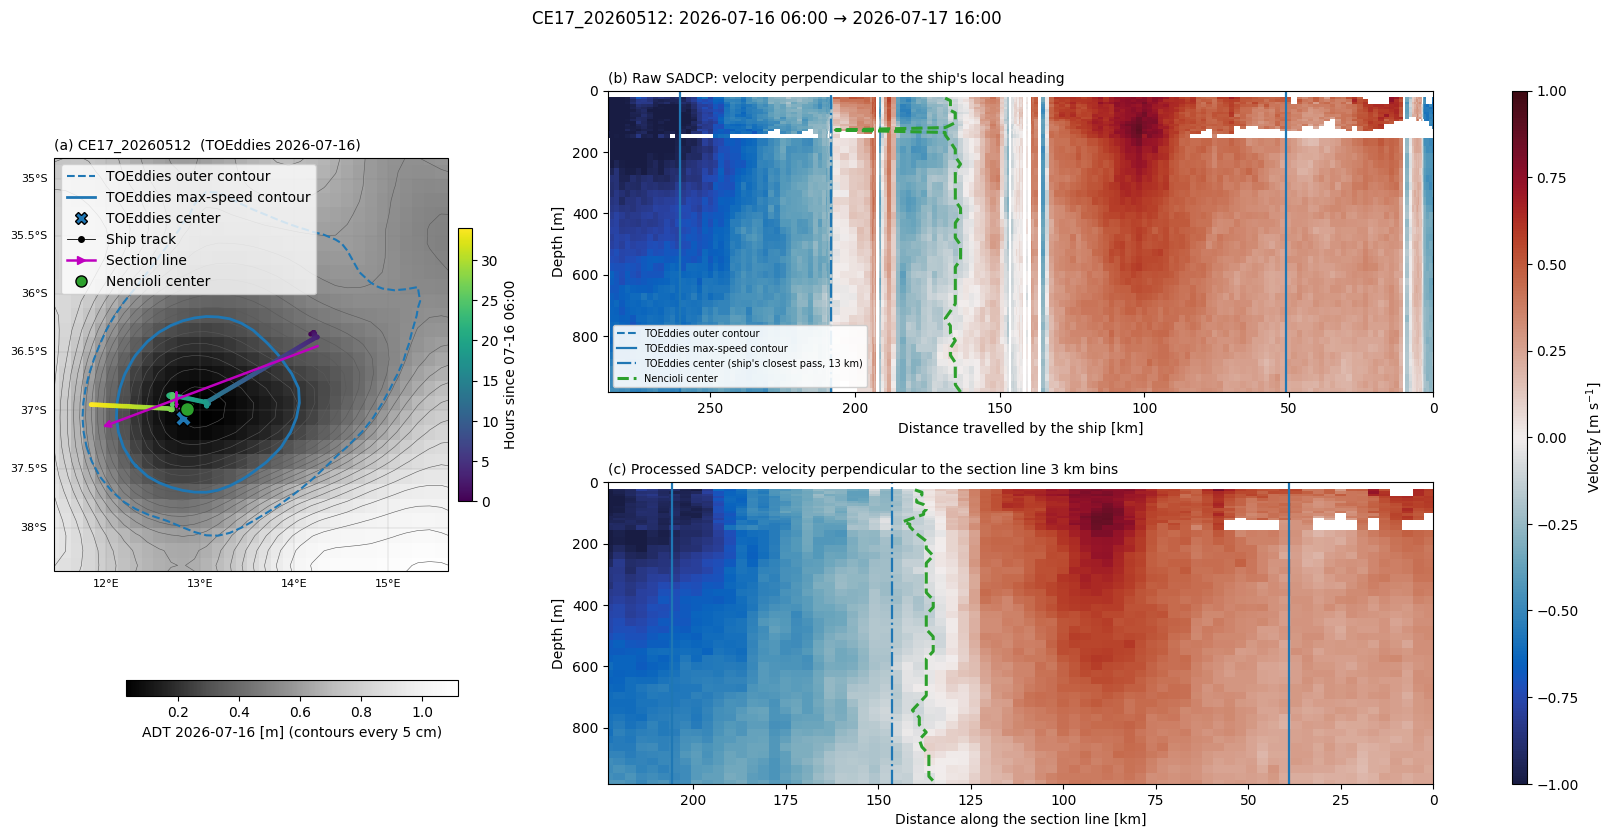

In [60]:
res = three_panel_figure(EDDIES[CURR])